# Tugas Kelompok Sistem Rekomendasi
## Prediksi Rating dan Rekomendasi Item dengan User-Based CF, Item-Based CF, dan Matrix Factorization

| | |
|---|---|
| Kelompok | 5 |
| Anggota | Naufal Rafif Hidayat - 103012300403<br>Muhammad Alivio Putra - 103012300098<br>Akbar Jundi Pradita - 103012300081<br>Raffa Anung El Haqqi - 103012300163<br>Naufal Thafhan - 103012300284 |
| Mata Kuliah | Sistem Rekomendasi |
| Dataset | Goodbooks-10k (subset 1.000 user) |

### Tujuan

1. Melakukan prediksi rating dan rekomendasi item menggunakan tiga metode:
   *user-based collaborative filtering*, *item-based collaborative filtering*, dan *matrix factorization*.
2. Menguji ketiga metode dengan metrik MAE, MSE, RMSE, NMSE, dan NDCG.

### Daftar Isi

1. Persiapan library
2. Dataset
3. Eksplorasi data
4. Pembagian data train dan data uji
5. Fungsi metrik evaluasi
6. User-Based Collaborative Filtering
7. Item-Based Collaborative Filtering
8. Matrix Factorization (Stochastic Gradient Descent)
9. Contoh rekomendasi Top 10
10. Perbandingan ketiga metode
11. Eksperimen parameter
12. Validasi silang 5-fold
13. Analisis dan kesimpulan

## 1. Persiapan Library

Library yang digunakan:

- `numpy` dan `pandas` untuk pengolahan data dan operasi matriks
- `scikit-learn` untuk `cosine_similarity` dan `train_test_split`
- `matplotlib` untuk visualisasi

Seed acak ditetapkan agar hasil dapat direproduksi.

In [1]:
import os
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
np.random.seed(SEED)

DATA_DIR = "data"
ASSET_DIR = "assets"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(ASSET_DIR, exist_ok=True)

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"User-Based CF": "#2563eb", "Item-Based CF": "#16a34a", "Matrix Factorization": "#dc2626"}

## 2. Dataset

Dataset yang digunakan adalah Goodbooks-10k (Zając, 2017), yaitu kumpulan rating buku dari situs Goodreads.
Dataset ini berisi riwayat pemberian rating (*user history*) dari user terhadap buku:

- 5.976.479 rating dengan skala 1 sampai 5 (rating eksplisit)
- 53.424 user, setiap user minimal memberi 19 rating
- 10.000 buku terpopuler di Goodreads

File yang dipakai:

| File | Isi |
|---|---|
| `ratings.csv` | `user_id`, `book_id`, `rating` |
| `books.csv` | informasi buku: `book_id`, judul, penulis, tahun terbit |

Sel berikut otomatis mengunduh dataset (sekitar 75 MB) dari repository GitHub Goodbooks-10k jika belum tersedia,
sehingga notebook juga bisa langsung dijalankan di Google Colab.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/"
GB_DIR = os.path.join(DATA_DIR, "goodbooks")
os.makedirs(GB_DIR, exist_ok=True)

def download(filename):
    url, path = BASE_URL + filename, os.path.join(GB_DIR, filename)
    try:
        urllib.request.urlretrieve(url, path)
    except Exception:
        # beberapa komputer Windows tidak memiliki sertifikat root yang lengkap
        import ssl, shutil, certifi
        ctx = ssl.create_default_context(cafile=certifi.where())
        with urllib.request.urlopen(url, context=ctx) as r, open(path, "wb") as f:
            shutil.copyfileobj(r, f)

for filename in ["ratings.csv", "books.csv"]:
    if not os.path.exists(os.path.join(GB_DIR, filename)):
        print("Mengunduh", filename, "...")
        download(filename)

print("File dataset:", sorted(os.listdir(GB_DIR)))

File dataset: ['books.csv', 'ratings.csv']


In [3]:
ratings_full = pd.read_csv(os.path.join(GB_DIR, "ratings.csv"))
books = pd.read_csv(os.path.join(GB_DIR, "books.csv"))

print(f"Dataset lengkap: {len(ratings_full):,} rating, {ratings_full.user_id.nunique():,} user, "
      f"{ratings_full.book_id.nunique():,} buku")
ratings_full.head()

Dataset lengkap: 5,976,479 rating, 53,424 user, 10,000 buku


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


### 2.1 Pembentukan subset

Dataset lengkap berisi hampir 6 juta rating. Matriks user x item berukuran 53.424 x 10.000 terlalu besar untuk
user-based CF yang menghitung similarity antar semua pasangan user. Karena itu dibentuk subset dengan dua langkah:

1. Mengambil 1.000 user secara acak (`seed = 42`) beserta seluruh riwayat rating mereka.
2. Menyaring secara berulang (*k-core*) sehingga setiap user dan setiap buku memiliki minimal 10 rating.
   Buku yang hanya dirating sedikit user tidak cukup untuk menghitung similarity antaritem secara andal.

ID user dan buku kemudian dipetakan ulang menjadi nomor urut mulai dari 1 agar mudah dijadikan indeks matriks.

In [4]:
rng_subset = np.random.default_rng(SEED)
selected_users = rng_subset.choice(ratings_full["user_id"].unique(), 1000, replace=False)
subset = ratings_full[ratings_full["user_id"].isin(selected_users)]

MIN_RATINGS = 10
while True:
    cu = subset.groupby("user_id").size()
    ci = subset.groupby("book_id").size()
    filtered = subset[subset["user_id"].isin(cu[cu >= MIN_RATINGS].index) &
                      subset["book_id"].isin(ci[ci >= MIN_RATINGS].index)]
    if len(filtered) == len(subset):
        break
    subset = filtered

# pemetaan ulang ID menjadi nomor urut 1..n
user_map = {u: i + 1 for i, u in enumerate(sorted(subset["user_id"].unique()))}
book_map = {b: i + 1 for i, b in enumerate(sorted(subset["book_id"].unique()))}
ratings = pd.DataFrame({
    "user_id": subset["user_id"].map(user_map).values,
    "item_id": subset["book_id"].map(book_map).values,
    "book_id": subset["book_id"].values,
    "rating": subset["rating"].values,
})

book_info = books.set_index("book_id")
titles = pd.Series({new: f"{book_info.loc[old, 'title']} ({book_info.loc[old, 'authors'].split(',')[0]})"
                    for old, new in book_map.items()})

print(f"Subset: {len(ratings):,} rating, {ratings.user_id.nunique():,} user, {ratings.item_id.nunique():,} buku")
ratings.head()

Subset: 84,139 rating, 996 user, 2,618 buku


,user_id,item_id,book_id,rating
0,3,1714,1842,2
1,3,26,26,3
2,3,287,287,3
3,3,11,11,4
4,3,111,111,4


In [5]:
n_users = ratings["user_id"].max()
n_items = ratings["item_id"].max()
n_ratings = len(ratings)
R_MIN, R_MAX = ratings["rating"].min(), ratings["rating"].max()
sparsity = 1 - n_ratings / (n_users * n_items)

print(f"Jumlah rating    : {n_ratings:,}")
print(f"Jumlah user  : {n_users:,}")
print(f"Jumlah item/buku : {n_items:,}")
print(f"Skala rating     : {R_MIN} - {R_MAX}")
print(f"Rata-rata rating : {ratings['rating'].mean():.4f}")
print(f"Sparsity matriks : {sparsity:.2%} sel kosong")

Jumlah rating    : 84,139
Jumlah user  : 996
Jumlah item/buku : 2,618
Skala rating     : 1 - 5
Rata-rata rating : 3.9179
Sparsity matriks : 96.77% sel kosong


## 3. Eksplorasi Data

Eksplorasi dilakukan untuk memahami karakteristik data sebelum membangun model:
distribusi nilai rating, jumlah rating per user, dan jumlah rating per buku.

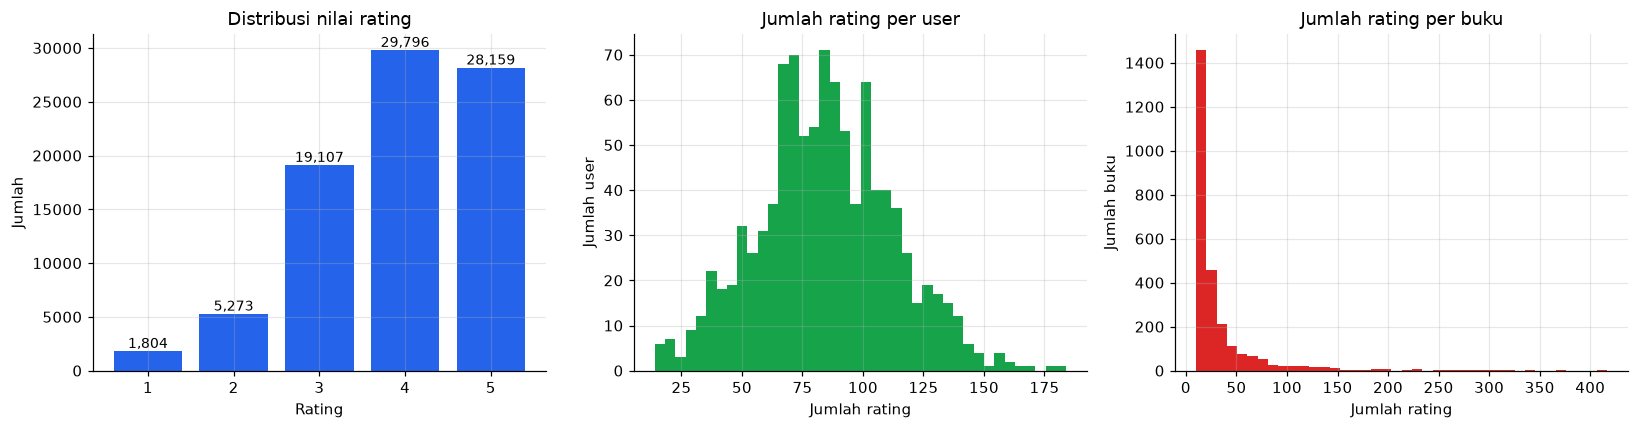

Rating per user: min=14, median=84, max=184
Rating per buku : min=10, median=18, max=417
Buku dengan < 20 rating: 1399 buku


In [6]:
per_user = ratings.groupby("user_id").size()
per_item = ratings.groupby("item_id").size()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
counts = ratings["rating"].value_counts().sort_index()
ax[0].bar(counts.index, counts.values, color="#2563eb")
for x, y in zip(counts.index, counts.values):
    ax[0].text(x, y, f"{y:,}", ha="center", va="bottom", fontsize=9)
ax[0].set(title="Distribusi nilai rating", xlabel="Rating", ylabel="Jumlah")

ax[1].hist(per_user, bins=40, color="#16a34a")
ax[1].set(title="Jumlah rating per user", xlabel="Jumlah rating", ylabel="Jumlah user")

ax[2].hist(per_item, bins=40, color="#dc2626")
ax[2].set(title="Jumlah rating per buku", xlabel="Jumlah rating", ylabel="Jumlah buku")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "eda_distribusi.png"), bbox_inches="tight")
plt.show()

print(f"Rating per user: min={per_user.min()}, median={per_user.median():.0f}, max={per_user.max()}")
print(f"Rating per buku : min={per_item.min()}, median={per_item.median():.0f}, max={per_item.max()}")
print(f"Buku dengan < 20 rating: {(per_item < 20).sum()} buku")

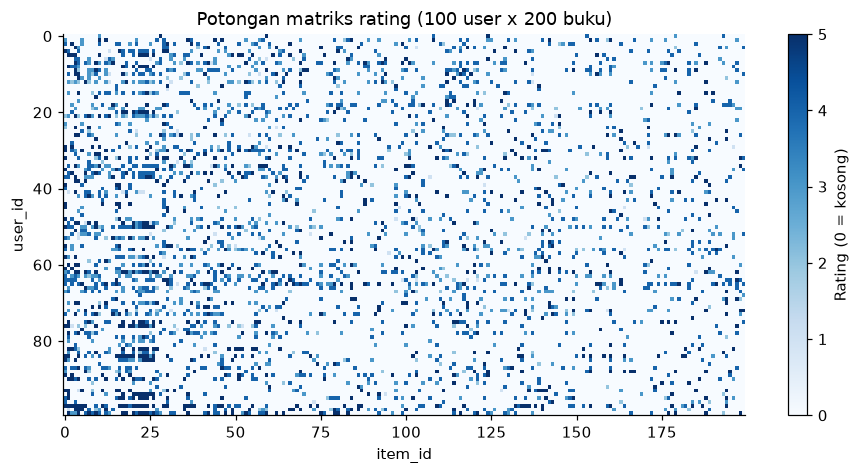

In [7]:
# Visualisasi sparsity: potongan 100 user x 200 buku pertama
sample = np.zeros((100, 200))
sub = ratings[(ratings.user_id <= 100) & (ratings.item_id <= 200)]
sample[sub.user_id - 1, sub.item_id - 1] = sub.rating

plt.figure(figsize=(10, 4.5))
plt.imshow(sample, aspect="auto", cmap="Blues", interpolation="nearest")
plt.colorbar(label="Rating (0 = kosong)")
plt.title("Potongan matriks rating (100 user x 200 buku)")
plt.xlabel("item_id"); plt.ylabel("user_id"); plt.grid(False)
plt.savefig(os.path.join(ASSET_DIR, "eda_sparsity.png"), bbox_inches="tight")
plt.show()

Pengamatan:

- Rating didominasi nilai 4 dan 5 (sekitar 69%), sehingga rata-rata rating sekitar 3,9. User Goodreads cenderung memberi rating tinggi.
- Distribusi jumlah rating per buku sangat miring (*long tail*): sebagian kecil buku sangat populer, sedangkan lebih dari separuh buku hanya mendapat 10 sampai 20 rating di subset.
- Setiap user memiliki riwayat yang cukup panjang (median 84 rating), tetapi sekitar 96,8% sel matriks tetap kosong. Kondisi ini disebut *sparsity problem*.

## 4. Pembagian Data Train dan Data Uji

Sebagian rating disembunyikan sebagai data uji (*data masking*).
Model hanya dilatih dengan data train, lalu diminta memprediksi rating yang disembunyikan.

- Data train: 80% rating
- Data uji: 20% rating
- `random_state = 42` agar ketiga metode diuji pada pembagian yang sama persis, sehingga perbandingannya adil.

Data train kemudian diubah menjadi matriks rating $R$ berukuran user x item, dengan nilai 0 untuk rating yang tidak diketahui.

In [8]:
train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=SEED)

def build_matrix(df):
    # Membentuk matriks rating user x item (0 = belum dirating)
    R = np.zeros((n_users, n_items))
    R[df["user_id"].values - 1, df["item_id"].values - 1] = df["rating"].values
    return R

R_train = build_matrix(train_df)

print(f"Data train : {len(train_df):,} rating")
print(f"Data uji   : {len(test_df):,} rating")
print(f"Ukuran matriks R_train : {R_train.shape}")
print("User di data uji yang tidak ada di data train:",
      len(set(test_df.user_id) - set(train_df.user_id)))
print("Item di data uji yang tidak ada di data train    :",
      len(set(test_df.item_id) - set(train_df.item_id)))

Data train : 67,311 rating
Data uji   : 16,828 rating
Ukuran matriks R_train : (996, 2618)
User di data uji yang tidak ada di data train: 0
Item di data uji yang tidak ada di data train    : 0


User atau item pada data uji yang tidak muncul di data train (*cold-start*) tidak dapat diprediksi dari tetangga.
Untuk kasus seperti ini, ketiga metode memakai nilai cadangan (*fallback* atau *default back-off*), yaitu rata-rata rating user.

## 5. Fungsi Metrik Evaluasi

Metrik dibagi menjadi dua kelompok, yaitu metrik akurasi prediksi rating dan metrik kualitas urutan rekomendasi (Baizal dan Wibowo).

Metrik akurasi prediksi rating dihitung pada seluruh pasangan user-item di data uji $T$:

$$MAE = \frac{\sum_{(u,i) \in T} |\hat{r}_{u,i} - r_{u,i}|}{|T|} \qquad
MSE = \frac{\sum_{(u,i) \in T} (\hat{r}_{u,i} - r_{u,i})^2}{|T|}$$

$$RMSE = \sqrt{MSE} \qquad NMSE = \frac{MSE}{r_{max} - r_{min}}$$

dengan $r_{max} = 5$ dan $r_{min} = 1$ adalah rating maksimum dan minimum pada dataset.

Metrik kualitas urutan rekomendasi (Top N) menggunakan NDCG (Järvelin dan Kekäläinen, 2002):

$$DCG_l = \sum_{i=1}^{l} \frac{rel_i}{\log_2(i+1)} \qquad NDCG_l = \frac{DCG_l}{IDCG_l}$$

$IDCG_l$ adalah DCG dari urutan ideal (item diurutkan dari relevansi tertinggi).

Cara penerapan NDCG pada data rating: untuk setiap user, item-item miliknya di data uji diurutkan berdasarkan rating prediksi,
lalu relevansi setiap posisi diambil dari rating asli. NDCG dihitung sampai posisi $l = 10$ (NDCG@10), kemudian dirata-rata untuk semua user.
Dua variasi relevansi dihitung:

- NDCG@10 (graded): $rel_i$ = rating asli (1 sampai 5)
- NDCG@10 (biner): $rel_i = 1$ jika rating asli $\geq 4$, selain itu 0

*Catatan:* sebagian literatur menggunakan *gain* $2^{rel_i} - 1$. Notebook ini menggunakan $rel_i$ secara langsung untuk DCG maupun IDCG.

In [9]:
def mae(y_true, y_pred):
    return np.mean(np.abs(y_pred - y_true))

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def nmse(y_true, y_pred, r_max=R_MAX, r_min=R_MIN):
    return mse(y_true, y_pred) / (r_max - r_min)

def dcg(relevances):
    rel = np.asarray(relevances, dtype=float)
    positions = np.arange(1, len(rel) + 1)
    return np.sum(rel / np.log2(positions + 1))

def ndcg_at_k(test, P, k=10, binary=False):
    # test: DataFrame data uji, P: matriks prediksi rating (user x item)
    scores = []
    for u, group in test.groupby("user_id"):
        item_idx = group["item_id"].values - 1
        actual = group["rating"].values.astype(float)
        rel = (actual >= 4).astype(float) if binary else actual
        predicted = P[u - 1, item_idx]
        order = np.argsort(-predicted, kind="stable")[:k]  # urutan menurut prediksi
        ideal = np.sort(rel)[::-1][:k]                       # urutan ideal
        idcg = dcg(ideal)
        if idcg > 0:
            scores.append(dcg(rel[order]) / idcg)
    return np.mean(scores)

def evaluate(name, P, test=None):
    test = test_df if test is None else test
    y_true = test["rating"].values.astype(float)
    y_pred = P[test["user_id"].values - 1, test["item_id"].values - 1]
    return {"Metode": name,
            "MAE": mae(y_true, y_pred), "MSE": mse(y_true, y_pred),
            "RMSE": rmse(y_true, y_pred), "NMSE": nmse(y_true, y_pred),
            "NDCG@10": ndcg_at_k(test, P, 10),
            "NDCG@10 (biner)": ndcg_at_k(test, P, 10, binary=True)}

### Pengujian fungsi metrik

Fungsi metrik diuji dengan contoh perhitungan yang hasilnya sudah diketahui:

1. NDCG dengan urutan relevansi hasil sistem $[3, 2, 3, 0, 1, 2]$ dan urutan ideal $[3, 3, 2, 2, 1, 0]$.
   Nilai acuan: $DCG_6 = 6{,}861$, $IDCG_6 = 7{,}141$, $NDCG_6 = 0{,}961$.
2. MAE dengan rating asli $[3, 4, 4, 5]$ dan prediksi $[5{,}0;\ 3{,}5;\ 2{,}0;\ 2{,}5]$. Nilai acuan: $MAE = 1{,}75$.

In [10]:
dcg6, idcg6 = dcg([3, 2, 3, 0, 1, 2]), dcg([3, 3, 2, 2, 1, 0])
print(f"DCG_6  = {dcg6:.3f}  (nilai acuan: 6.861)")
print(f"IDCG_6 = {idcg6:.3f}  (nilai acuan: 7.141)")
print(f"NDCG_6 = {dcg6 / idcg6:.3f}  (nilai acuan: 0.961)")

y_true_ex = np.array([3, 4, 4, 5]); y_pred_ex = np.array([5.0, 3.5, 2.0, 2.5])
print(f"MAE contoh = {mae(y_true_ex, y_pred_ex):.2f}  (nilai acuan: 1.75)")
print(f"MSE = {mse(y_true_ex, y_pred_ex):.4f}, RMSE = {rmse(y_true_ex, y_pred_ex):.4f}, "
      f"NMSE = {nmse(y_true_ex, y_pred_ex):.4f}")

DCG_6  = 6.861  (nilai acuan: 6.861)
IDCG_6 = 7.141  (nilai acuan: 7.141)
NDCG_6 = 0.961  (nilai acuan: 0.961)
MAE contoh = 1.75  (nilai acuan: 1.75)
MSE = 3.6250, RMSE = 1.9039, NMSE = 0.9062


## 6. User-Based Collaborative Filtering

User-based CF berangkat dari asumsi bahwa user yang memiliki selera serupa di masa lalu akan memiliki selera serupa di masa depan (Jannach dkk., 2010).
Untuk memprediksi rating user aktif $a$ terhadap item $p$, dicari user lain (tetangga) yang mirip dengan $a$ dan sudah merating $p$.

Langkah-langkah:

1. Hitung rata-rata rating setiap user $\bar{r}_a$.
2. Hitung kemiripan antar user dengan Pearson correlation:
$$sim(a,b) = \frac{\sum_{p \in P}(r_{a,p} - \bar{r}_a)(r_{b,p} - \bar{r}_b)}{\sqrt{\sum_{p \in P}(r_{a,p} - \bar{r}_a)^2}\sqrt{\sum_{p \in P}(r_{b,p} - \bar{r}_b)^2}}$$
3. Pilih tetangga (*neighborhood selection*): ambil $k$ user paling mirip yang sudah merating item $p$ dan memiliki similarity positif.
4. Hitung prediksi rating:
$$pred(a,p) = \bar{r}_a + \frac{\sum_{b \in N} sim(a,b)\,(r_{b,p} - \bar{r}_b)}{\sum_{b \in N} sim(a,b)}$$
5. Jika tidak ada tetangga yang memenuhi syarat, prediksi = $\bar{r}_a$ (*fallback*).

### 6.1 Verifikasi dengan contoh kasus Alice

Sebelum diterapkan ke dataset besar, perhitungan diuji pada contoh kasus Alice dari Jannach dkk. (2010).
Nilai acuan: $sim(Alice, User1) = 0{,}85$, $sim(Alice, User2) = 0{,}70$ (nilai tepatnya 0,7071, sehingga tampil 0,71 jika dibulatkan), dan prediksi rating Alice untuk Item5 = $4{,}87$.

In [11]:
alice = pd.DataFrame(
    [[5, 3, 4, 4, np.nan],
     [3, 1, 2, 3, 3],
     [4, 3, 4, 3, 5],
     [3, 3, 1, 5, 4],
     [1, 5, 5, 2, 1]],
    index=["Alice", "User1", "User2", "User3", "User4"],
    columns=["Item1", "Item2", "Item3", "Item4", "Item5"])

def pearson(a, b):
    # Pearson correlation pada item yang dirating oleh kedua user
    mask = ~np.isnan(a) & ~np.isnan(b)
    da, db = a[mask] - a[mask].mean(), b[mask] - b[mask].mean()
    return (da @ db) / (np.sqrt(da @ da) * np.sqrt(db @ db))

target = alice.loc["Alice"].values
sims = pd.Series({u: pearson(target, alice.loc[u].values) for u in alice.index[1:]})
print("Similarity Alice dengan user lain:")
print(sims.round(2).to_string())

# Prediksi dengan k = 2 tetangga terdekat (User1 dan User2)
neighbors = sims.sort_values(ascending=False).index[:2]
r_alice = np.nanmean(target)
num = sum(sims[b] * (alice.loc[b, "Item5"] - alice.loc[b].mean()) for b in neighbors)
den = sum(sims[b] for b in neighbors)
print(f"\nTetangga terpilih: {list(neighbors)}")
print(f"Prediksi rating Alice untuk Item5 = {r_alice + num / den:.2f}  (nilai acuan: 4.87)")

Similarity Alice dengan user lain:
User1    0.85
User2    0.71
User3    0.00
User4   -0.79

Tetangga terpilih: ['User1', 'User2']
Prediksi rating Alice untuk Item5 = 4.87  (nilai acuan: 4.87)


### 6.2 Implementasi untuk dataset Goodbooks

Pada dataset besar, perhitungan Pearson untuk setiap pasangan user satu per satu terlalu lambat.
Karena itu perhitungan dilakukan dalam bentuk operasi matriks:

1. Buat matriks baru berisi selisih rating dengan rata-rata user (*mean-centering*). Sel kosong bernilai 0.
2. Hitung cosine similarity antarbaris matriks tersebut dengan `sklearn.metrics.pairwise.cosine_similarity`.
   Cosine similarity pada data yang sudah dikurangi rata-ratanya setara dengan Pearson correlation.
3. Untuk setiap user, tetangga diurutkan dari yang paling mirip, lalu untuk setiap item diambil $k$ tetangga pertama yang sudah merating item tersebut.

Hasilnya adalah matriks prediksi rating lengkap (user x buku) yang dipakai untuk evaluasi dan rekomendasi.
Nilai $k = 30$ dipilih karena jumlah tetangga 20 sampai 50 umumnya sudah memadai untuk dataset rating eksplisit (Jannach dkk., 2010).

In [12]:
def user_means(R):
    mask = R > 0
    counts = mask.sum(axis=1)
    global_mean = R[mask].mean()
    return np.where(counts > 0, R.sum(axis=1) / np.maximum(counts, 1), global_mean)

def user_similarity(R):
    # Langkah 1-2: mean-centering lalu cosine similarity antar user
    mask = R > 0
    mu = user_means(R)
    centered = (R - mu[:, None]) * mask
    S = cosine_similarity(centered)
    np.fill_diagonal(S, 0)          # user tidak dihitung sebagai tetangga dirinya sendiri
    return S, centered, mu

def predict_user_based(R, k=30, S=None):
    mask = R > 0
    S_, centered, mu = user_similarity(R)
    S = S_ if S is None else S
    P = np.zeros_like(R, dtype=float)
    for a in range(R.shape[0]):
        order = np.argsort(-S[a])                  # tetangga dari yang paling mirip
        s_sorted = S[a, order]
        rated = mask[order] & (s_sorted > 0)[:, None]  # hanya similarity positif
        top_k = rated & (np.cumsum(rated, axis=0) <= k)   # k tetangga pertama per item
        w = s_sorted[:, None] * top_k
        num = (w * centered[order]).sum(axis=0)
        den = w.sum(axis=0)
        P[a] = np.where(den > 0, mu[a] + num / np.where(den > 0, den, 1), mu[a])
    return np.clip(P, R_MIN, R_MAX)

In [13]:
start = time.time()
P_user = predict_user_based(R_train, k=30)
print(f"Waktu komputasi User-Based CF: {time.time() - start:.1f} detik")

result_user = evaluate("User-Based CF", P_user)
pd.DataFrame([result_user]).set_index("Metode")

Waktu komputasi User-Based CF: 51.9 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
User-Based CF,0.6809,0.794,0.8911,0.1985,0.9097,0.8293


In [14]:
# Contoh: 5 user paling mirip dengan user 1
S_user, _, _ = user_similarity(R_train)
top5 = np.argsort(-S_user[0])[:5]
pd.DataFrame({"user_id": top5 + 1, "similarity": S_user[0, top5]})

,user_id,similarity
0,425,0.1474
1,697,0.1063
2,865,0.0912
3,191,0.0893
4,73,0.0873


## 7. Item-Based Collaborative Filtering

Item-based CF membuat rekomendasi berdasarkan kemiripan antaritem, yang dihitung dari rating yang diberikan banyak user terhadap kedua item tersebut (Sarwar dkk., 2001).
Pendekatan ini lebih skalabel ketika jumlah user jauh lebih banyak daripada jumlah item, karena matriks kemiripan item dapat dihitung terlebih dahulu (*offline*).

Langkah-langkah:

1. Hitung kemiripan antaritem. Dua ukuran dibandingkan:
   - *Cosine similarity*:
   $$sim(\vec{a}, \vec{b}) = \frac{\vec{a} \cdot \vec{b}}{|\vec{a}| \times |\vec{b}|}$$
   - *Adjusted cosine similarity*: rating dikurangi rata-rata user terlebih dahulu, sehingga perbedaan kebiasaan merating antar user ikut diperhitungkan:
   $$sim(a,b) = \frac{\sum_{u \in U}(r_{u,a} - \bar{r}_u)(r_{u,b} - \bar{r}_u)}{\sqrt{\sum_{u \in U}(r_{u,a} - \bar{r}_u)^2}\sqrt{\sum_{u \in U}(r_{u,b} - \bar{r}_u)^2}}$$
2. Pilih item tetangga: dari item-item yang sudah dirating user $u$, ambil $k$ item yang paling mirip dengan item target $p$ (similarity positif).
3. Hitung prediksi rating:
$$pred(u,p) = \frac{\sum_{i \in ratedItems(u)} sim(i,p) \cdot r_{u,i}}{\sum_{i \in ratedItems(u)} sim(i,p)}$$
4. Jika tidak ada item tetangga, prediksi = rata-rata rating user.

### 7.1 Verifikasi dengan contoh kasus Alice

In [15]:
def item_similarity(R, adjusted=True):
    mask = R > 0
    X = (R - user_means(R)[:, None]) * mask if adjusted else R
    S = cosine_similarity(X.T)      # kemiripan antar kolom (item)
    np.fill_diagonal(S, 0)
    return S

R_alice = alice.fillna(0).values
for adjusted in [False, True]:
    S_a = item_similarity(R_alice, adjusted=adjusted)
    sims_item5 = S_a[4, :4]
    w = np.clip(sims_item5, 0, None)                  # hanya similarity positif
    pred = (w @ R_alice[0, :4]) / w.sum()
    label = "Adjusted cosine" if adjusted else "Cosine"
    print(f"{label:15s} sim(Item5, Item1..4) = {np.round(sims_item5, 3)} -> prediksi Alice-Item5 = {pred:.2f}")

Cosine          sim(Item5, Item1..4) = [0.759 0.673 0.622 0.812] -> prediksi Alice-Item5 = 4.03
Adjusted cosine sim(Item5, Item1..4) = [ 0.714 -0.853 -0.764  0.433] -> prediksi Alice-Item5 = 4.62


Dengan *adjusted cosine*, Item5 paling mirip dengan Item1 dan berlawanan dengan Item2 dan Item3, sehingga prediksi untuk Alice
lebih mengikuti rating Alice pada Item1 (5) dan Item4 (4). Dengan *cosine* biasa, semua item terlihat mirip karena seluruh rating bernilai positif.

### 7.2 Implementasi untuk dataset Goodbooks

In [16]:
def predict_item_based(R, k=30, adjusted=True, S=None):
    mask = R > 0
    S = item_similarity(R, adjusted) if S is None else S
    mu = user_means(R)
    P = np.zeros_like(R, dtype=float)
    for u in range(R.shape[0]):
        rated = np.where(mask[u])[0]          # item yang sudah dirating user u
        r_u = R[u, rated]
        S_u = np.clip(S[:, rated], 0, None)   # similarity semua item terhadap item yang dirating
        if len(rated) > k:                    # ambil k item paling mirip
            idx = np.argpartition(-S_u, k - 1, axis=1)[:, :k]
            S_k = np.take_along_axis(S_u, idx, axis=1)
            r_k = r_u[idx]
        else:
            S_k, r_k = S_u, np.broadcast_to(r_u, S_u.shape)
        num = (S_k * r_k).sum(axis=1)
        den = S_k.sum(axis=1)
        P[u] = np.where(den > 0, num / np.where(den > 0, den, 1), mu[u])
    return np.clip(P, R_MIN, R_MAX)

In [17]:
start = time.time()
P_item_cos = predict_item_based(R_train, k=30, adjusted=False)
print(f"Item-Based CF (cosine)          : {time.time() - start:.1f} detik")

start = time.time()
P_item = predict_item_based(R_train, k=30, adjusted=True)
print(f"Item-Based CF (adjusted cosine) : {time.time() - start:.1f} detik")

result_item_cos = evaluate("Item-Based CF (cosine)", P_item_cos)
result_item = evaluate("Item-Based CF (adjusted cosine)", P_item)
pd.DataFrame([result_item_cos, result_item]).set_index("Metode")

Item-Based CF (cosine)          : 8.8 detik


Item-Based CF (adjusted cosine) : 8.6 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
Item-Based CF (cosine),0.6721,0.7608,0.8723,0.1902,0.9113,0.8325
Item-Based CF (adjusted cosine),0.6606,0.7558,0.8693,0.1889,0.9107,0.8316


In [18]:
# Contoh: 5 buku paling mirip dengan buku yang paling banyak dirating di subset (adjusted cosine)
S_item = item_similarity(R_train, adjusted=True)
ref = per_item.idxmax() - 1
popular = per_item.reindex(range(1, n_items + 1), fill_value=0).values >= 50   # hanya buku dengan >= 50 rating
cand = np.where(popular)[0]
cand = cand[cand != ref]
top = cand[np.argsort(-S_item[ref, cand])[:5]]
print("Buku acuan:", titles.loc[ref + 1])
pd.DataFrame({"item_id": top + 1, "judul": titles.loc[top + 1].values, "similarity": S_item[ref, top]})

Buku acuan: The Hunger Games (The Hunger Games, #1) (Suzanne Collins)


,item_id,judul,similarity
0,17,"Catching Fire (The Hunger Games, #2) (Suzanne ...",0.4112
1,31,The Help (Kathryn Stockett),0.1997
2,12,"Divergent (Divergent, #1) (Veronica Roth)",0.1912
3,24,Harry Potter and the Goblet of Fire (Harry Pot...,0.1744
4,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.1701


*Adjusted cosine* memberikan error yang lebih kecil daripada cosine biasa (MAE, MSE, RMSE, dan NMSE), karena perbedaan kebiasaan merating antar user ikut diperhitungkan.
Nilai NDCG keduanya hampir sama. Untuk perbandingan utama, Item-Based CF memakai adjusted cosine.

## 8. Matrix Factorization (Stochastic Gradient Descent)

Matrix factorization mengasumsikan adanya sejumlah fitur laten yang menentukan bagaimana user merating item
(misalnya seberapa suka user pada buku fantasi, dan seberapa kuat unsur fantasi pada sebuah buku) (Koren dkk., 2009).
Matriks rating $R$ berukuran $|U| \times |D|$ didekati dengan perkalian dua matriks yang lebih kecil:

$$R \approx P \times Q^T = \hat{R}$$

- $P$ ($|U| \times K$): setiap baris adalah kekuatan hubungan seorang user dengan $K$ fitur laten
- $Q$ ($|D| \times K$): setiap baris adalah kekuatan hubungan sebuah item dengan $K$ fitur laten

Langkah-langkah:

1. Inisialisasi $P$ dan $Q$ dengan nilai acak kecil.
2. Untuk setiap rating yang diketahui $r_{ij}$, hitung prediksi dan error:
$$\hat{r}_{ij} = p_i^T q_j = \sum_{k=1}^{K} p_{ik} q_{kj} \qquad e_{ij} = r_{ij} - \hat{r}_{ij}$$
3. Perbarui $P$ dan $Q$ ke arah yang memperkecil error dengan *stochastic gradient descent* dan regularisasi $\beta$ (Yeung, 2010):
$$p'_{ik} = p_{ik} + \alpha\,(2 e_{ij} q_{kj} - \beta p_{ik}) \qquad q'_{kj} = q_{kj} + \alpha\,(2 e_{ij} p_{ik} - \beta q_{kj})$$
4. Ulangi untuk beberapa *epoch* hingga error konvergen.

Penyesuaian terhadap implementasi dasar matrix factorization (Yeung, 2010):

1. Implementasi dasar mengulang seluruh sel matriks (`for i ... for j ... if R[i][j] > 0`) sebanyak 5000 langkah. Untuk matriks berukuran ratusan ribu hingga jutaan sel cara ini sangat lambat,
   sehingga perulangan hanya dilakukan pada rating yang diketahui dengan urutan diacak setiap epoch (inti dari *stochastic* gradient descent).
2. Learning rate $\alpha = 0{,}005$ (lebih besar dari 0,0002 pada implementasi dasar) agar cukup 30 epoch untuk konvergen.
3. Ditambahkan bias (rata-rata global $\mu$, bias user $b_i$, bias item $b_j$), sehingga $\hat{r}_{ij} = \mu + b_i + b_j + p_i^T q_j$.
   Bias menangkap kecenderungan user yang selalu memberi rating tinggi/rendah dan buku yang memang disukai banyak orang. Versi tanpa bias juga dievaluasi sebagai pembanding.

In [19]:
def matrix_factorization(train, K=20, epochs=30, alpha=0.005, beta=0.2,
                         use_bias=True, test=None, seed=SEED, verbose=True):
    rng = np.random.default_rng(seed)
    P = rng.normal(0, 0.1, (n_users, K))     # matriks fitur laten user
    Q = rng.normal(0, 0.1, (n_items, K))     # matriks fitur laten item
    b_u = np.zeros(n_users)
    b_i = np.zeros(n_items)
    mu = train["rating"].mean() if use_bias else 0.0

    users = train["user_id"].values - 1
    its = train["item_id"].values - 1
    r = train["rating"].values.astype(float)
    history = {"epoch": [], "train_rmse": [], "test_rmse": []}

    for epoch in range(1, epochs + 1):
        for t in rng.permutation(len(r)):            # urutan rating diacak setiap epoch
            i, j = users[t], its[t]
            e = r[t] - (mu + b_u[i] + b_i[j] + P[i] @ Q[j])   # error e_ij
            if use_bias:
                b_u[i] += alpha * (2 * e - beta * b_u[i])
                b_i[j] += alpha * (2 * e - beta * b_i[j])
            p_old = P[i].copy()
            P[i] += alpha * (2 * e * Q[j] - beta * P[i])      # update p_ik
            Q[j] += alpha * (2 * e * p_old - beta * Q[j])     # update q_kj

        R_hat = mu + b_u[:, None] + b_i[None, :] + P @ Q.T
        history["epoch"].append(epoch)
        history["train_rmse"].append(rmse(r, R_hat[users, its]))
        if test is not None:
            yt = test["rating"].values.astype(float)
            history["test_rmse"].append(rmse(yt, np.clip(R_hat[test.user_id - 1, test.item_id - 1], R_MIN, R_MAX)))
        if verbose and (epoch == 1 or epoch % 5 == 0):
            msg = f"epoch {epoch:3d}  RMSE train = {history['train_rmse'][-1]:.4f}"
            if test is not None:
                msg += f"  RMSE uji = {history['test_rmse'][-1]:.4f}"
            print(msg)

    return np.clip(R_hat, R_MIN, R_MAX), history

In [20]:
start = time.time()
P_mf, hist_mf = matrix_factorization(train_df, K=20, epochs=30, alpha=0.005, beta=0.2,
                                     use_bias=True, test=test_df)
print(f"\nWaktu komputasi Matrix Factorization: {time.time() - start:.1f} detik")

result_mf = evaluate("Matrix Factorization", P_mf)
pd.DataFrame([result_mf]).set_index("Metode")

epoch   1  RMSE train = 0.8898  RMSE uji = 0.9108


epoch   5  RMSE train = 0.8352  RMSE uji = 0.8802


epoch  10  RMSE train = 0.8217  RMSE uji = 0.8791


epoch  15  RMSE train = 0.8095  RMSE uji = 0.8791


epoch  20  RMSE train = 0.7923  RMSE uji = 0.8777


epoch  25  RMSE train = 0.7692  RMSE uji = 0.8757


epoch  30  RMSE train = 0.7418  RMSE uji = 0.8746

Waktu komputasi Matrix Factorization: 27.9 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
Matrix Factorization,0.6839,0.7649,0.8746,0.1912,0.9073,0.8244


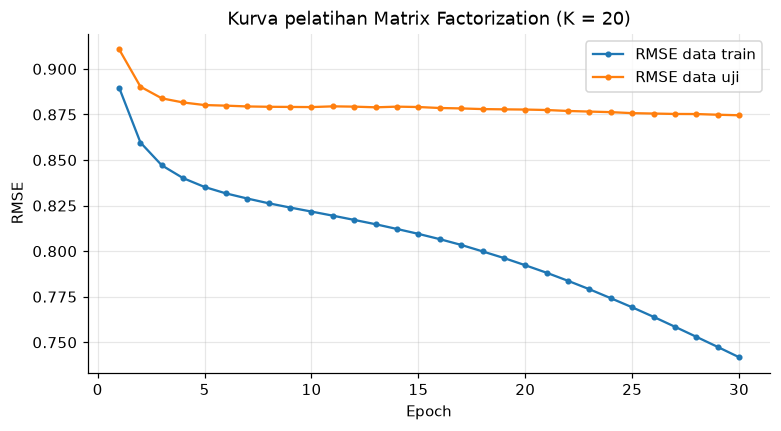

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(hist_mf["epoch"], hist_mf["train_rmse"], marker="o", ms=3, label="RMSE data train")
plt.plot(hist_mf["epoch"], hist_mf["test_rmse"], marker="o", ms=3, label="RMSE data uji")
plt.xlabel("Epoch"); plt.ylabel("RMSE")
plt.title("Kurva pelatihan Matrix Factorization (K = 20)")
plt.legend()
plt.savefig(os.path.join(ASSET_DIR, "mf_loss.png"), bbox_inches="tight")
plt.show()

RMSE data train terus turun, sedangkan RMSE data uji turun lalu mendatar. Regularisasi $\beta$ menjaga agar model tidak terlalu menghafal data train (*overfitting*).

Pembanding: Matrix Factorization tanpa bias (rumus prediksi $\hat{r}_{ij} = p_i^T q_j$ seperti implementasi dasar):

In [22]:
start = time.time()
P_mf_nobias, _ = matrix_factorization(train_df, K=20, epochs=30, alpha=0.005, beta=0.2,
                                      use_bias=False, verbose=False)
print(f"Waktu komputasi: {time.time() - start:.1f} detik")
result_mf_nobias = evaluate("Matrix Factorization (tanpa bias)", P_mf_nobias)
pd.DataFrame([result_mf_nobias, result_mf]).set_index("Metode")

Waktu komputasi: 26.2 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
Matrix Factorization (tanpa bias),0.6905,0.7657,0.8751,0.1914,0.9150,0.8389
Matrix Factorization,0.6839,0.7649,0.8746,0.1912,0.9073,0.8244


## 9. Contoh Rekomendasi Top 10

Rekomendasi dibuat dengan cara: prediksi rating seluruh buku yang belum dirating user (di data train), urutkan dari prediksi tertinggi, lalu ambil 10 teratas.
Agar rekomendasi tidak didominasi buku yang hanya dirating sedikit user, kandidat dibatasi pada buku yang memiliki minimal 20 rating di data train.
Pada User-Based dan Item-Based CF banyak buku memperoleh prediksi yang sama (sering tepat 5,0), sehingga jika prediksi sama,
buku yang lebih populer di data train didahulukan.

In [23]:
item_count_train = (R_train > 0).sum(axis=0)

def recommend(P, user_id, n=10, min_ratings=20):
    u = user_id - 1
    candidates = np.where((R_train[u] == 0) & (item_count_train >= min_ratings))[0]
    # urutkan menurut prediksi; jika prediksi sama, buku yang lebih populer didahulukan
    order = np.lexsort((-item_count_train[candidates], -P[u, candidates]))
    top = candidates[order[:n]]
    return pd.DataFrame({"item_id": top + 1, "judul": titles.loc[top + 1].values,
                         "prediksi": P[u, top].round(3)})

USER_EXAMPLE = 1
liked = train_df[(train_df.user_id == USER_EXAMPLE)].sort_values("rating", ascending=False).head(10)
print(f"Buku yang paling disukai user {USER_EXAMPLE} (data train):")
print(liked.assign(judul=titles.loc[liked.item_id].values)[["item_id", "judul", "rating"]].to_string(index=False))

Buku yang paling disukai user 1 (data train):
 item_id                                                                        judul  rating
    1294                                        Howl and Other Poems (Allen Ginsberg)       5
     484                                  The Brothers Karamazov (Fyodor Dostoyevsky)       5
      29                                       Romeo and Juliet (William Shakespeare)       5
    1952                                     The Complete Works (William Shakespeare)       5
      60              The Curious Incident of the Dog in the Night-Time (Mark Haddon)       5
     125                                                 Hamlet (William Shakespeare)       5
     925                                           Waiting for Godot (Samuel Beckett)       5
     229 Alice's Adventures in Wonderland & Through the Looking-Glass (Lewis Carroll)       5
     528                                 Much Ado About Nothing (William Shakespeare)       5
    1002      

In [24]:
recs = {name: recommend(P, USER_EXAMPLE) for name, P in
        [("User-Based CF", P_user), ("Item-Based CF", P_item), ("Matrix Factorization", P_mf)]}
for name, df_rec in recs.items():
    print(f"\nTop 10 rekomendasi untuk user {USER_EXAMPLE} - {name}")
    print(df_rec.to_string(index=False))


Top 10 rekomendasi untuk user 1 - User-Based CF
 item_id                                                                   judul  prediksi
     487                                           The Green Mile (Stephen King)       5.0
     735 The Little House Collection (Little House, #1-9) (Laura Ingalls Wilder)       5.0
     393                   Throne of Glass (Throne of Glass, #1) (Sarah J. Maas)       5.0
     389                     The Final Empire (Mistborn, #1) (Brandon Sanderson)       5.0
    1157                                       Cold Sassy Tree (Olive Ann Burns)       5.0
     537                                Hopeless (Hopeless, #1) (Colleen Hoover)       5.0
     600                     The Hero of Ages (Mistborn, #3) (Brandon Sanderson)       5.0
     717                   The Shadow Rising (Wheel of Time, #4) (Robert Jordan)       5.0
     533  Daughter of Smoke & Bone (Daughter of Smoke & Bone, #1) (Laini Taylor)       5.0
    1216                          The Tal

In [25]:
# Apakah rekomendasi tepat? Cek buku rekomendasi yang ternyata ada di data uji user tersebut
user_test = test_df[test_df.user_id == USER_EXAMPLE].set_index("item_id")["rating"]
for name, df_rec in recs.items():
    hit = df_rec[df_rec.item_id.isin(user_test.index)]
    info = ", ".join(f"{t} (rating asli {user_test[i]})" for i, t in zip(hit.item_id, hit.judul))
    print(f"{name:22s}: {len(hit)} buku ada di data uji -> {info if info else '-'}")

User-Based CF         : 0 buku ada di data uji -> -
Item-Based CF         : 0 buku ada di data uji -> -
Matrix Factorization  : 0 buku ada di data uji -> -


## 10. Perbandingan Ketiga Metode

Semua metode dievaluasi pada data uji yang sama (20% rating, `random_state = 42`).
Untuk MAE, MSE, RMSE, dan NMSE, semakin kecil semakin baik. Untuk NDCG, semakin besar semakin baik.

In [26]:
baseline_P = np.tile(user_means(R_train)[:, None], (1, n_items))
result_baseline = evaluate("Baseline (rata-rata user)", baseline_P)

main_results = pd.DataFrame([
    {**result_user, "Metode": "User-Based CF"},
    {**result_item, "Metode": "Item-Based CF"},
    {**result_mf, "Metode": "Matrix Factorization"},
]).set_index("Metode")

all_results = pd.DataFrame([result_baseline, result_user, result_item_cos, result_item,
                            result_mf_nobias, result_mf]).set_index("Metode")
all_results.to_csv(os.path.join(ASSET_DIR, "hasil_evaluasi.csv"))

def highlight(df):
    styles = pd.DataFrame("", index=df.index, columns=df.columns)
    for c in df.columns:
        best = df[c].idxmax() if c.startswith("NDCG") else df[c].idxmin()
        styles.loc[best, c] = "font-weight: bold; background-color: #dcfce7"
    return styles

print("Perbandingan utama (nilai terbaik ditebalkan):")
main_results.style.format("{:.4f}").apply(highlight, axis=None)

Perbandingan utama (nilai terbaik ditebalkan):


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
User-Based CF,0.6809,0.7940,0.8911,0.1985,0.9097,0.8293
Item-Based CF,0.6606,0.7558,0.8693,0.1889,0.9107,0.8316
Matrix Factorization,0.6839,0.7649,0.8746,0.1912,0.9073,0.8244


In [27]:
print("Perbandingan lengkap termasuk baseline dan variasi:")
all_results.style.format("{:.4f}").apply(highlight, axis=None)

Perbandingan lengkap termasuk baseline dan variasi:


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
Baseline (rata-rata user),0.7151,0.8271,0.9094,0.2068,0.8674,0.7402
User-Based CF,0.6809,0.7940,0.8911,0.1985,0.9097,0.8293
Item-Based CF (cosine),0.6721,0.7608,0.8723,0.1902,0.9113,0.8325
Item-Based CF (adjusted cosine),0.6606,0.7558,0.8693,0.1889,0.9107,0.8316
Matrix Factorization (tanpa bias),0.6905,0.7657,0.8751,0.1914,0.9150,0.8389
Matrix Factorization,0.6839,0.7649,0.8746,0.1912,0.9073,0.8244


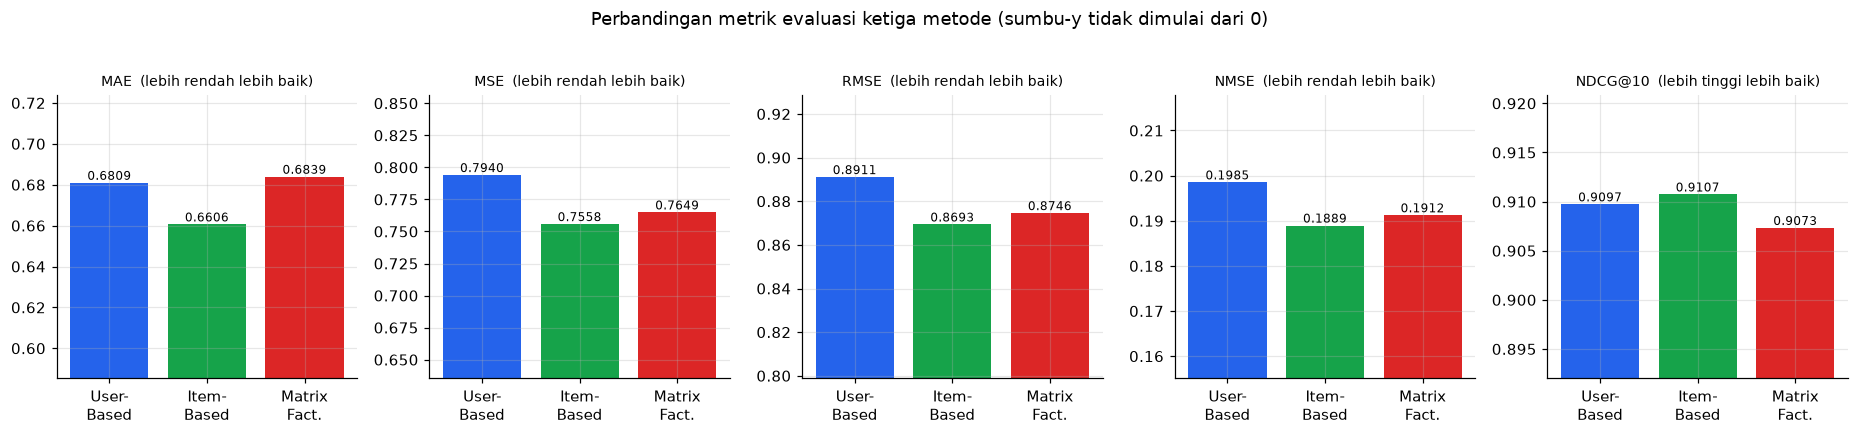

In [28]:
methods = main_results.index.tolist()
colors = [COLORS[m] for m in methods]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, metric in zip(axes, ["MAE", "MSE", "RMSE", "NMSE", "NDCG@10"]):
    vals = main_results[metric]
    bars = ax.bar(range(len(methods)), vals, color=colors)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
    lo, hi = vals.min(), vals.max()
    ax.set_ylim(lo - (hi - lo) * 3 - 0.005, hi + (hi - lo) * 1.5 + 0.005)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(["User-\nBased", "Item-\nBased", "Matrix\nFact."])
    ax.set_title(metric + ("  (lebih tinggi lebih baik)" if metric.startswith("NDCG") else "  (lebih rendah lebih baik)"), fontsize=9)
plt.suptitle("Perbandingan metrik evaluasi ketiga metode (sumbu-y tidak dimulai dari 0)", y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "perbandingan_metrik.png"), bbox_inches="tight")
plt.show()

## 11. Eksperimen Parameter

### 11.1 Pengaruh jumlah tetangga $k$ pada User-Based dan Item-Based CF

Nilai $k$ yang terlalu besar membawa *noise* dari tetangga yang kurang mirip,
sedangkan $k$ yang terlalu kecil (di bawah 10) menurunkan kualitas prediksi (Jannach dkk., 2010). Eksperimen berikut menguji hal tersebut.
Matriks similarity cukup dihitung sekali, lalu dipakai ulang untuk setiap nilai $k$.

In [29]:
K_VALUES = [5, 10, 20, 30, 50, 100]
S_user, _, _ = user_similarity(R_train)
S_item = item_similarity(R_train, adjusted=True)

rows = []
start = time.time()
for k in K_VALUES:
    rows.append({**evaluate("User-Based CF", predict_user_based(R_train, k=k, S=S_user)), "k": k})
    rows.append({**evaluate("Item-Based CF", predict_item_based(R_train, k=k, S=S_item)), "k": k})
k_results = pd.DataFrame(rows)
k_results.to_csv(os.path.join(ASSET_DIR, "hasil_eksperimen_k.csv"), index=False)
print(f"Waktu eksperimen: {time.time() - start:.1f} detik")
k_results.pivot(index="k", columns="Metode", values=["MAE", "RMSE", "NDCG@10"]).round(4)

Waktu eksperimen: 463.2 detik


MAE                        RMSE                     NDCG@10  \
Metode Item-Based CF User-Based CF Item-Based CF User-Based CF Item-Based CF   
k                                                                              
5             0.6674        0.7069        0.9004        0.9267        0.9092   
10            0.6592        0.6869        0.8759        0.9007        0.9096   
20            0.6599        0.6818        0.8698        0.8928        0.9107   
30            0.6606        0.6809        0.8693        0.8911        0.9107   
50            0.6611        0.6807        0.8696        0.8905        0.9107   
100           0.6611        0.6815        0.8696        0.8909        0.9107   

                      
Metode User-Based CF  
k                     
5             0.9042  
10            0.9084  
20            0.9090  
30            0.9097  
50            0.9097  
100           0.9094

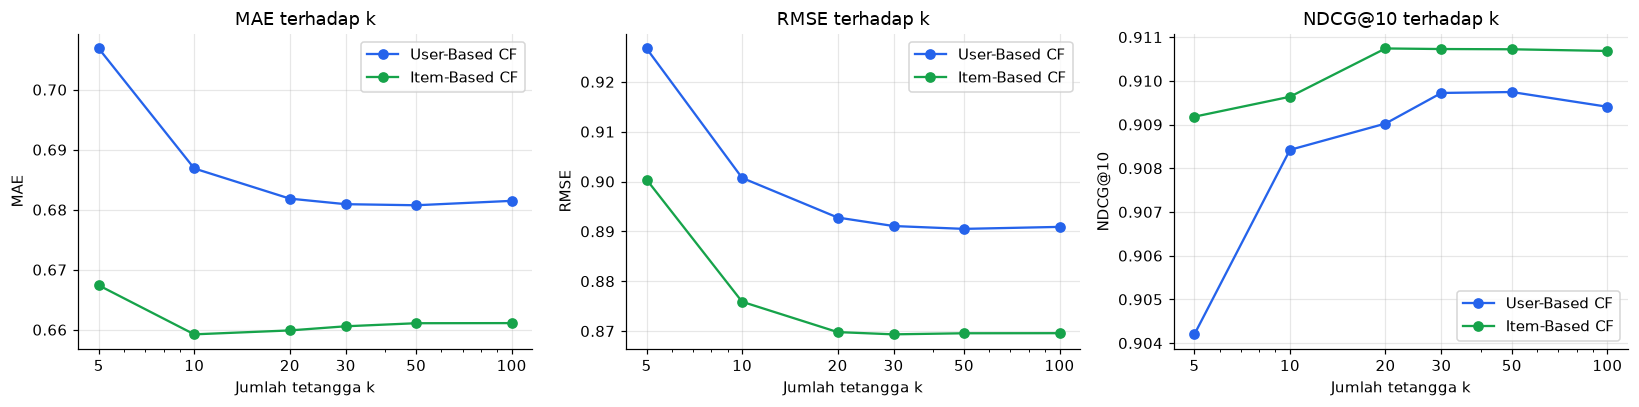

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["MAE", "RMSE", "NDCG@10"]):
    for m in ["User-Based CF", "Item-Based CF"]:
        d = k_results[k_results.Metode == m]
        ax.plot(d["k"], d[metric], marker="o", label=m, color=COLORS[m])
    ax.set_xscale("log"); ax.set_xticks(K_VALUES); ax.set_xticklabels(K_VALUES)
    ax.set(title=f"{metric} terhadap k", xlabel="Jumlah tetangga k", ylabel=metric)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "eksperimen_k.png"), bbox_inches="tight")
plt.show()

### 11.2 Pengaruh jumlah fitur laten $K$ pada Matrix Factorization

In [31]:
FACTORS = [5, 10, 20, 50, 100]
rows = []
start = time.time()
for K in FACTORS:
    P_k, _ = matrix_factorization(train_df, K=K, epochs=30, verbose=False)
    rows.append({**evaluate("Matrix Factorization", P_k), "K": K})
factor_results = pd.DataFrame(rows).set_index("K").drop(columns="Metode")
factor_results.to_csv(os.path.join(ASSET_DIR, "hasil_eksperimen_faktor.csv"))
print(f"Waktu eksperimen: {time.time() - start:.1f} detik")
factor_results.round(4)

Waktu eksperimen: 184.8 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
K,,,,,,
5,0.6866,0.7686,0.8767,0.1921,0.9073,0.8243
10,0.6876,0.7703,0.8777,0.1926,0.9071,0.8229
20,0.6839,0.7649,0.8746,0.1912,0.9073,0.8244
50,0.6829,0.7618,0.8728,0.1905,0.9082,0.8265
100,0.6815,0.7590,0.8712,0.1897,0.9095,0.8297


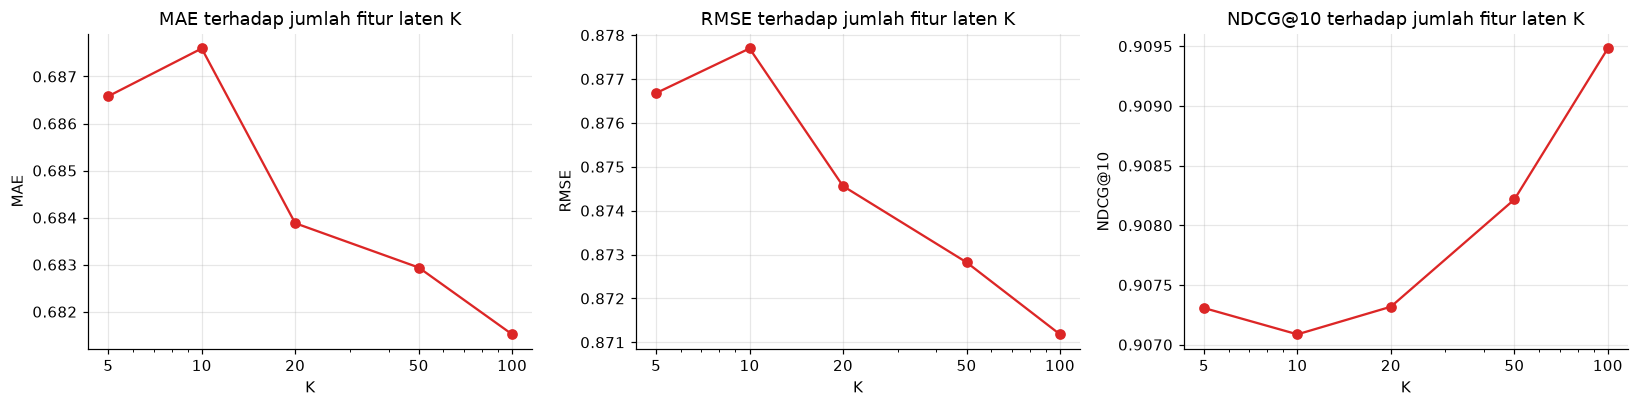

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["MAE", "RMSE", "NDCG@10"]):
    ax.plot(factor_results.index, factor_results[metric], marker="o", color=COLORS["Matrix Factorization"])
    ax.set_xscale("log"); ax.set_xticks(FACTORS); ax.set_xticklabels(FACTORS)
    ax.set(title=f"{metric} terhadap jumlah fitur laten K", xlabel="K", ylabel=metric)
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "eksperimen_faktor.png"), bbox_inches="tight")
plt.show()

## 12. Validasi Silang 5-Fold

Evaluasi diulang beberapa kali agar hasil tidak bias oleh satu kali pembagian data acak (*N-fold cross validation*).
Data rating dibagi menjadi 5 bagian secara acak dengan `KFold(n_splits=5, shuffle=True, random_state=42)`.
Setiap bagian bergiliran menjadi data uji (20% rating), sehingga data uji kelima fold saling lepas.

Ketiga metode dijalankan dengan parameter yang sama seperti bagian 6 sampai 8 ($k = 30$, $K = 20$), kemudian dihitung rata-rata dan simpangan bakunya.

In [33]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
start = time.time()
for fold, (tr_idx, te_idx) in enumerate(kfold.split(ratings), start=1):
    tr, te = ratings.iloc[tr_idx], ratings.iloc[te_idx]
    R_fold = build_matrix(tr)
    preds = {
        "User-Based CF": predict_user_based(R_fold, k=30),
        "Item-Based CF": predict_item_based(R_fold, k=30, adjusted=True),
        "Matrix Factorization": matrix_factorization(tr, K=20, epochs=30, verbose=False)[0],
    }
    for name, P in preds.items():
        cv_rows.append({**evaluate(name, P, test=te), "Fold": fold})
    print(f"Fold {fold} selesai ({time.time() - start:.0f} detik)")

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(os.path.join(ASSET_DIR, "hasil_cv.csv"), index=False)

Fold 1 selesai (126 detik)


Fold 2 selesai (253 detik)


Fold 3 selesai (374 detik)


Fold 4 selesai (502 detik)


Fold 5 selesai (627 detik)


In [34]:
metric_cols = ["MAE", "MSE", "RMSE", "NMSE", "NDCG@10", "NDCG@10 (biner)"]
order = ["User-Based CF", "Item-Based CF", "Matrix Factorization"]
cv_mean = cv_results.groupby("Metode")[metric_cols].mean().loc[order]
cv_std = cv_results.groupby("Metode")[metric_cols].std().loc[order]
cv_summary = cv_mean.round(4).astype(str) + " ± " + cv_std.round(4).astype(str)
print("Rata-rata ± simpangan baku dari 5 fold:")
cv_summary

Rata-rata ± simpangan baku dari 5 fold:


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
User-Based CF,0.6813 ± 0.0025,0.7878 ± 0.0058,0.8876 ± 0.0033,0.197 ± 0.0014,0.9108 ± 0.0008,0.8299 ± 0.0015
Item-Based CF,0.6597 ± 0.0032,0.7481 ± 0.0091,0.8649 ± 0.0053,0.187 ± 0.0023,0.9119 ± 0.0013,0.8317 ± 0.0028
Matrix Factorization,0.6805 ± 0.0032,0.7559 ± 0.0087,0.8694 ± 0.005,0.189 ± 0.0022,0.9103 ± 0.0016,0.8302 ± 0.0032


In [35]:
print("Hasil per fold (RMSE):")
cv_results.pivot(index="Fold", columns="Metode", values="RMSE")[order].round(4)

Hasil per fold (RMSE):


Metode,User-Based CF,Item-Based CF,Matrix Factorization
Fold,,,
1,0.8911,0.8693,0.8746
2,0.8882,0.8655,0.8707
3,0.8903,0.8707,0.8735
4,0.8844,0.8595,0.8640
5,0.8841,0.8595,0.8643


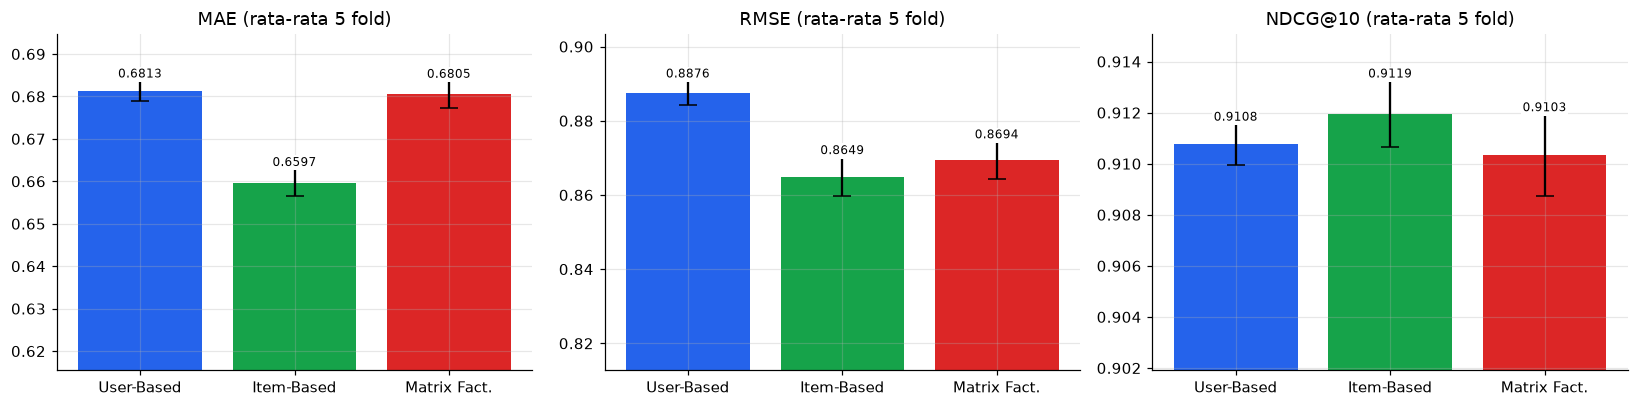

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["MAE", "RMSE", "NDCG@10"]):
    ax.bar(range(3), cv_mean[metric], yerr=cv_std[metric], capsize=6, color=[COLORS[m] for m in order])
    for x, (v, s) in enumerate(zip(cv_mean[metric], cv_std[metric])):
        ax.text(x, v + s, f"{v:.4f}", ha="center", va="bottom", fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    lo = (cv_mean[metric] - cv_std[metric]).min()
    hi = (cv_mean[metric] + cv_std[metric]).max()
    ax.set_ylim(lo - (hi - lo) * 1.5, hi + (hi - lo) * 0.4)
    ax.set_xticks(range(3)); ax.set_xticklabels(["User-Based", "Item-Based", "Matrix Fact."])
    ax.set_title(f"{metric} (rata-rata 5 fold)")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "cv_perbandingan.png"), bbox_inches="tight")
plt.show()

## 13. Analisis dan Kesimpulan

### 13.1 Ringkasan hasil

Data uji utama (split 80:20, `random_state = 42`):

| Metode | MAE | MSE | RMSE | NMSE | NDCG@10 | NDCG@10 (biner) |
|---|---|---|---|---|---|---|
| Baseline (rata-rata user) | 0,7151 | 0,8271 | 0,9094 | 0,2068 | 0,8674 | 0,7402 |
| User-Based CF (k = 30) | 0,6809 | 0,7940 | 0,8911 | 0,1985 | 0,9097 | 0,8293 |
| Item-Based CF (adjusted cosine, k = 30) | 0,6606 | 0,7558 | 0,8693 | 0,1889 | 0,9107 | 0,8316 |
| Matrix Factorization (K = 20) | 0,6839 | 0,7649 | 0,8746 | 0,1912 | 0,9073 | 0,8244 |

Validasi silang 5-fold (rata-rata ± simpangan baku):

| Metode | MAE | RMSE | NMSE | NDCG@10 | NDCG@10 (biner) |
|---|---|---|---|---|---|
| User-Based CF | 0,6813 ± 0,0025 | 0,8876 ± 0,0033 | 0,1970 ± 0,0014 | 0,9108 ± 0,0008 | 0,8299 ± 0,0015 |
| Item-Based CF | 0,6597 ± 0,0032 | 0,8649 ± 0,0053 | 0,1870 ± 0,0023 | 0,9119 ± 0,0013 | 0,8317 ± 0,0028 |
| Matrix Factorization | 0,6805 ± 0,0032 | 0,8694 ± 0,0050 | 0,1890 ± 0,0022 | 0,9103 ± 0,0016 | 0,8302 ± 0,0032 |

### 13.2 Analisis

#### Perbandingan dengan baseline

Baseline yang selalu menebak rata-rata rating user menghasilkan RMSE 0,9094. Ketiga metode menurunkan RMSE menjadi 0,8693 sampai 0,8911,
atau membaik sekitar 2 sampai 4,4%, dan menaikkan NDCG@10 biner dari 0,740 menjadi sekitar 0,82 sampai 0,83.
Peningkatan ini tergolong kecil karena user Goodreads cenderung konsisten memberi rating tinggi
(69% rating bernilai 4 atau 5), sehingga rata-rata rating user saja sudah cukup akurat.

#### Item-Based CF sebagai metode terbaik

Item-Based CF dengan adjusted cosine memperoleh error terkecil pada data uji utama (RMSE 0,8693) maupun validasi silang (RMSE 0,8649 ± 0,0053),
dan menang di kelima fold. Matrix Factorization berada di posisi kedua (RMSE 0,8694 ± 0,0050), sedangkan User-Based CF paling lemah (0,8876 ± 0,0033).
Hubungan antaritem pada data buku sangat kuat, terutama untuk buku dalam satu seri atau satu penulis. Contohnya, buku yang paling mirip dengan
The Hunger Games adalah Catching Fire dengan similarity 0,41, jauh di atas buku lain. Item-based CF memanfaatkan pola ini secara langsung (Sarwar dkk., 2001).

#### Lemahnya User-Based CF

Subset hanya berisi 996 user, sehingga pilihan tetangga terbatas. Similarity user terdekat untuk user 1 hanya 0,15, karena dua user rata-rata
hanya berbagi sedikit buku dari 2.618 buku yang tersedia. Sebaliknya, setiap buku dirating oleh banyak user yang sama-sama membaca buku populer,
sehingga similarity antaritem lebih andal. Kondisi ini sejalan dengan alasan item-based CF diusulkan untuk data dengan jumlah user yang besar dan beragam.

#### Matrix Factorization

Matrix Factorization mendekati Item-Based CF dengan selisih RMSE sekitar 0,005, lebih kecil dari simpangan baku antarfold.
Kurva pelatihan menunjukkan RMSE data train turun dari 0,890 menjadi 0,742, sedangkan RMSE data uji hanya turun dari 0,911 menjadi 0,875.
Selisih yang cukup besar ini menandakan kecenderungan *overfitting*, karena jumlah parameter (996 + 2.618 baris fitur laten) relatif besar
dibandingkan rating yang tersedia. Penambahan fitur laten memberi perbaikan kecil (RMSE 0,8767 pada K = 5 menjadi 0,8712 pada K = 100).

#### Cosine dan adjusted cosine

Adjusted cosine memberikan error lebih kecil daripada cosine biasa (RMSE 0,8693 dibanding 0,8723), karena perbedaan kebiasaan merating antar user
ikut diperhitungkan. Namun NDCG keduanya hampir sama (0,9107 dan 0,9113), sehingga keunggulan adjusted cosine terutama pada ketepatan nilai rating.

#### Pengaruh jumlah tetangga k

Dengan k = 5, RMSE paling buruk (0,9267 untuk User-Based dan 0,9004 untuk Item-Based) karena prediksi hanya bergantung pada sedikit tetangga.
Error terkecil dicapai pada k = 30 untuk Item-Based (0,8693) dan k = 50 untuk User-Based (0,8905). Setelah k = 20, perubahan error sangat kecil,
sejalan dengan rentang 20 sampai 50 tetangga yang umum digunakan (Jannach dkk., 2010).

#### Metrik error dan NDCG

MAE, MSE, RMSE, dan NMSE mengukur ketepatan nilai rating, sedangkan NDCG mengukur ketepatan urutan item. Keduanya tidak selalu sejalan:
Matrix Factorization tanpa bias memiliki RMSE sedikit lebih buruk (0,8751) daripada versi dengan bias (0,8746), tetapi NDCG-nya paling tinggi
pada data uji utama (0,9150). Pada validasi silang, selisih NDCG ketiga metode sangat kecil (0,910 sampai 0,912), sehingga dari sisi urutan
ketiga metode hampir setara.

Nilai NDCG graded terlihat tinggi (bahkan baseline 0,867) karena NDCG dihitung dengan mengurutkan buku yang sudah dirating user di data uji
dan semua rating bernilai positif. NDCG biner (relevan jika rating $\geq 4$) lebih tegas membedakan metode dari baseline.

#### Prediksi yang sama pada rekomendasi Top 10

Pada User-Based dan Item-Based CF, banyak buku memperoleh prediksi yang sama, sering tepat 5,0. Item-based CF menghitung rata-rata tertimbang
rating user pada buku-buku yang mirip, sehingga untuk user yang banyak memberi rating 5, prediksinya ikut bernilai 5,0. Akibatnya urutan
rekomendasi tidak dapat dibedakan hanya dari prediksi, sehingga digunakan popularitas buku sebagai penentu urutan tambahan.
Matrix Factorization tidak mengalami masalah ini karena skornya bervariasi, sehingga lebih cocok untuk menyusun daftar rekomendasi.

#### Kelebihan dan kekurangan ketiga metode

| Aspek | User-Based CF | Item-Based CF | Matrix Factorization |
|---|---|---|---|
| Akurasi (RMSE 5-fold) | 0,8876 | 0,8649 | 0,8694 |
| Kemudahan dijelaskan | Mudah ("user yang mirip dengan Anda menyukai...") | Mudah ("karena Anda menyukai buku X...") | Sulit, fitur laten tidak bermakna langsung |
| Skalabilitas | Kurang, similarity antar user O(m²) | Lebih baik, similarity item dapat dihitung terlebih dahulu | Baik saat prediksi, tetapi perlu pelatihan |
| Rekomendasi Top 10 | Banyak prediksi sama | Banyak prediksi sama | Skor bervariasi |
| Parameter utama | k tetangga | k tetangga, jenis similarity | K, $\alpha$, $\beta$, epoch |

### 13.3 Kesimpulan

1. Ketiga metode berhasil memprediksi rating dan membuat rekomendasi Top 10 dari riwayat rating user Goodbooks-10k, dan semuanya lebih akurat daripada baseline rata-rata user.
2. Item-Based CF dengan adjusted cosine memberikan hasil terbaik: RMSE 0,8693 pada data uji utama dan 0,8649 ± 0,0053 pada validasi silang 5-fold, serta menang di kelima fold.
3. Matrix Factorization berada di posisi kedua dengan selisih yang kecil dan menghasilkan skor yang lebih bervariasi untuk menyusun rekomendasi, sedangkan User-Based CF paling lemah karena similarity antar user rendah.
4. Pemilihan parameter berpengaruh: adjusted cosine menurunkan error dibandingkan cosine biasa, jumlah tetangga terbaik berada di kisaran 20 sampai 50, dan penambahan fitur laten pada MF memberi peningkatan kecil.
5. Metrik error dan metrik ranking mengukur hal berbeda, sehingga evaluasi sistem rekomendasi sebaiknya memakai keduanya.

### Daftar Pustaka

1. Baizal, Z. K. A. dan Wibowo, A. T. *Sistem Rekomendasi*. Bandung: Telkom University.
2. Jannach, D., Zanker, M., Felfernig, A., dan Friedrich, G. (2010). *Recommender Systems: An Introduction*. Cambridge: Cambridge University Press.
3. Järvelin, K. dan Kekäläinen, J. (2002). Cumulated Gain-Based Evaluation of IR Techniques. *ACM Transactions on Information Systems*, 20(4), 422-446.
4. Koren, Y., Bell, R., dan Volinsky, C. (2009). Matrix Factorization Techniques for Recommender Systems. *Computer*, 42(8), 30-37.
5. Sarwar, B., Karypis, G., Konstan, J., dan Riedl, J. (2001). Item-Based Collaborative Filtering Recommendation Algorithms. *Proceedings of the 10th International Conference on World Wide Web*, 285-295.
6. Yeung, A. A. (2010). *Matrix Factorization: A Simple Tutorial and Implementation in Python*. quuxlabs.com.
7. Zając, Z. (2017). *Goodbooks-10k: A New Dataset for Book Recommendations*. FastML. https://github.com/zygmuntz/goodbooks-10k